# Proyecto Final – Ciencia de Datos en Acción
## Análisis de incidentes de soporte técnico y predicción de tiempos de resolución

**Universidad EAN**

**Asignatura:** DataXperience - Grupo 1 - Cuarto Ciclo

**Individual:** Ivan Dario Delgado Perez

**Fecha:** 21 de Noviembre de 2026

### Introducción
La gestión de incidentes tecnológicos es fundamental para garantizar la continuidad de los servicios y mejorar la atención a los usuarios. Este proyecto aplica herramientas de ciencia de datos para analizar el comportamiento de los incidentes, identificar patrones y evaluar la posibilidad de predecir sus tiempos de resolución.

### Objetivo general
Analizar un conjunto de datos de incidentes tecnológicos mediante técnicas de limpieza, estadística descriptiva, visualización y modelado predictivo, con el propósito de identificar oportunidades de mejora en la gestión del soporte técnico.

### Justificación
El proyecto se relaciona con el entorno profesional de la gestión de servicios tecnológicos, permitiendo aplicar los conocimientos adquiridos en el curso a situaciones reales de soporte, administración de sistemas y continuidad operativa.

### Fuente de datos
Incident Management Process Enriched Event Log – UCI Machine Learning Repository.

---
## Etapa 1. Fundamentos y herramientas de la ciencia de datos
### 1.1. Importación de librerías y carga del conjunto de datos

In [1]:
# Importación de librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Carga del dataset público de UCI
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00498/incident_event_log.zip"

data = pd.read_csv(url, compression="zip", na_values="?")

# Verificación de la carga
print("Dataset cargado correctamente")
print("Número de filas:", data.shape[0])
print("Número de columnas:", data.shape[1])

# Visualización de los primeros registros
display(data.head())


/tmp/ipykernel_585/279011155.py:10: DtypeWarning: Columns (19,31) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv(url, compression="zip", na_values="?")


Dataset cargado correctamente
Número de filas: 141712
Número de columnas: 36


,number,incident_state,active,reassignment_count,reopen_count,sys_mod_count,made_sla,caller_id,opened_by,opened_at,...,u_priority_confirmation,notify,problem_id,rfc,vendor,caused_by,closed_code,resolved_by,resolved_at,closed_at
0,INC0000045,New,True,0,0,0,True,Caller 2403,Opened by 8,29/2/2016 01:16,...,False,Do Not Notify,NaN,NaN,NaN,NaN,code 5,Resolved by 149,29/2/2016 11:29,5/3/2016 12:00
1,INC0000045,Resolved,True,0,0,2,True,Caller 2403,Opened by 8,29/2/2016 01:16,...,False,Do Not Notify,NaN,NaN,NaN,NaN,code 5,Resolved by 149,29/2/2016 11:29,5/3/2016 12:00
2,INC0000045,Resolved,True,0,0,3,True,Caller 2403,Opened by 8,29/2/2016 01:16,...,False,Do Not Notify,NaN,NaN,NaN,NaN,code 5,Resolved by 149,29/2/2016 11:29,5/3/2016 12:00
3,INC0000045,Closed,False,0,0,4,True,Caller 2403,Opened by 8,29/2/2016 01:16,...,False,Do Not Notify,NaN,NaN,NaN,NaN,code 5,Resolved by 149,29/2/2016 11:29,5/3/2016 12:00
4,INC0000047,New,True,0,0,0,True,Caller 2403,Opened by 397,29/2/2016 04:40,...,False,Do Not Notify,NaN,NaN,NaN,NaN,code 5,Resolved by 81,1/3/2016 09:52,6/3/2016 10:00


### 1.2. Exploración inicial del conjunto de datos

Se realiza una revisión de la estructura del conjunto de datos, identificando los tipos de variables, la cantidad de incidentes únicos, los valores faltantes y los registros duplicados.

Esta exploración permite establecer las acciones necesarias para mejorar la calidad de los datos antes del análisis estadístico.

In [2]:
# Exploración inicial del conjunto de datos

print("Dimensiones del dataset:", data.shape)
print("Incidentes únicos:", data["number"].nunique())
print("Filas duplicadas exactas:", data.duplicated().sum())

# Información general de las variables
print("\nInformación del dataset:")
data.info()

# Identificación de valores faltantes
resumen_calidad = pd.DataFrame({
    "Tipo de dato": data.dtypes.astype(str),
    "Valores nulos": data.isnull().sum(),
    "Porcentaje de nulos": (data.isnull().mean() * 100).round(2),
    "Valores únicos": data.nunique()
})

print("\nResumen de calidad de los datos:")
display(resumen_calidad.sort_values(
    "Porcentaje de nulos", ascending=False
))

# Distribución inicial de prioridades
print("\nDistribución de prioridades por evento:")
display(data["priority"].value_counts())


Dimensiones del dataset: (141712, 36)
Incidentes únicos: 24918
Filas duplicadas exactas: 0

Información del dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 141712 entries, 0 to 141711
Data columns (total 36 columns):
 #   Column                   Non-Null Count   Dtype 
---  ------                   --------------   ----- 
 0   number                   141712 non-null  object
 1   incident_state           141712 non-null  object
 2   active                   141712 non-null  bool  
 3   reassignment_count       141712 non-null  int64 
 4   reopen_count             141712 non-null  int64 
 5   sys_mod_count            141712 non-null  int64 
 6   made_sla                 141712 non-null  bool  
 7   caller_id                141683 non-null  object
 8   opened_by                136877 non-null  object
 9   opened_at                141712 non-null  object
 10  sys_created_by           88636 non-null   object
 11  sys_created_at           88636 non-null   object
 12  sys_updated

,Tipo de dato,Valores nulos,Porcentaje de nulos,Valores únicos
caused_by,object,141689,99.98,3
vendor,object,141468,99.83,4
cmdb_ci,object,141267,99.69,50
rfc,object,140721,99.30,181
problem_id,object,139417,98.38,252
sys_created_by,object,53076,37.45,185
sys_created_at,object,53076,37.45,11552
u_symptom,object,32964,23.26,525
assigned_to,object,27496,19.40,234
assignment_group,object,14213,10.03,78



Distribución de prioridades por evento:


,count
priority,
3 - Moderate,132452
4 - Low,4030
2 - High,2972
1 - Critical,2258


### 1.3. Hallazgos de la exploración inicial

El conjunto de datos contiene 141.712 registros, 36 variables y 24.918 incidentes únicos. No se encontraron filas duplicadas exactas; sin embargo, cada incidente puede presentar múltiples registros asociados a su evolución durante el proceso de atención.

Se identificaron 29 variables de tipo objeto, 3 variables numéricas enteras y 4 variables booleanas.

Los principales hallazgos relacionados con la calidad de los datos son:

- Cinco variables presentan porcentajes de valores faltantes superiores al 98 %, por lo que se excluirán del análisis.
- Las fechas se encuentran almacenadas como texto y requieren una transformación.
- La fecha de resolución presenta un 2,22 % de valores faltantes en los registros originales.
- La prioridad moderada representa aproximadamente el 93,47 % de los eventos registrados.
- Es necesario consolidar los registros para obtener una única observación por incidente.

Estos hallazgos permiten establecer los criterios de limpieza y transformación necesarios para realizar un análisis estadístico confiable y construir posteriormente un modelo predictivo.

### 1.4. Limpieza y transformación de los datos

En esta sección se realiza la depuración del conjunto de datos mediante la selección de variables relevantes, la conversión de fechas, el tratamiento de valores faltantes y la consolidación de los registros por incidente.

Adicionalmente, se construye una nueva variable denominada tiempo_resolucion_horas, que representa el tiempo transcurrido entre la apertura y la resolución de cada incidente.

Esta variable será fundamental para el análisis estadístico y constituirá la variable objetivo del modelo predictivo.

In [3]:
# Limpieza y transformación de los datos

# 1. Crear una copia para conservar los datos originales
datos = data.copy()

# 2. Seleccionar las variables relevantes
columnas = [
    "number",
    "incident_state",
    "reassignment_count",
    "reopen_count",
    "sys_mod_count",
    "made_sla",
    "opened_at",
    "sys_updated_at",
    "resolved_at",
    "closed_at",
    "contact_type",
    "category",
    "impact",
    "urgency",
    "priority",
    "assignment_group"
]

datos = datos[columnas].copy()

# 3. Convertir las fechas a formato datetime
columnas_fecha = [
    "opened_at",
    "sys_updated_at",
    "resolved_at",
    "closed_at"
]

for columna in columnas_fecha:
    datos[columna] = pd.to_datetime(
        datos[columna],
        dayfirst=True,
        errors="coerce"
    )

# 4. Ordenar cronológicamente los eventos
datos = datos.sort_values(
    ["number", "sys_updated_at", "sys_mod_count"],
    na_position="first"
)

# 5. Conservar los datos iniciales para el modelo predictivo
variables_iniciales = [
    "number", "priority", "impact",
    "urgency", "category", "contact_type"
]

datos_iniciales = datos.drop_duplicates(
    subset="number", keep="first"
)[variables_iniciales].copy()

# 6. Conservar el último registro de cada incidente
datos = datos.drop_duplicates(
    subset="number",
    keep="last"
).copy()

print("Incidentes después de la consolidación:", len(datos))

# 7. Tratar valores faltantes categóricos
datos["category"] = datos["category"].fillna("No registrada")
datos["assignment_group"] = datos["assignment_group"].fillna(
    "No registrado"
)

# 8. Calcular tiempo de resolución en horas
datos["tiempo_resolucion_horas"] = (
    datos["resolved_at"] - datos["opened_at"]
).dt.total_seconds() / 3600

# 9. Identificar tiempos faltantes o inconsistentes
print("Tiempos de resolución nulos:",
      datos["tiempo_resolucion_horas"].isnull().sum())

print("Tiempos de resolución negativos:",
      (datos["tiempo_resolucion_horas"] < 0).sum())

# 10. Excluir incidentes sin tiempo válido de resolución
datos_limpios = datos.dropna(
    subset=["tiempo_resolucion_horas"]
).copy()

datos_limpios = datos_limpios[
    datos_limpios["tiempo_resolucion_horas"] >= 0
].copy()

datos_limpios = datos_limpios.reset_index(drop=True)

# 11. Mostrar resultados
print("\nRESULTADOS DE LA LIMPIEZA")
print("Registros originales:", len(data))
print("Incidentes únicos originales:", data["number"].nunique())
print("Incidentes válidos:", len(datos_limpios))
print("Variables finales:", datos_limpios.shape[1])
print("Duplicados por incidente:",
      datos_limpios["number"].duplicated().sum())

print("\nPrimeros registros del dataset depurado:")
display(datos_limpios.head())

print("\nValores nulos después de la limpieza:")
display(datos_limpios.isnull().sum())

print("\nResumen de tiempos de resolución en horas:")
display(datos_limpios["tiempo_resolucion_horas"].describe())


Incidentes después de la consolidación: 24918
Tiempos de resolución nulos: 1556
Tiempos de resolución negativos: 0

RESULTADOS DE LA LIMPIEZA
Registros originales: 141712
Incidentes únicos originales: 24918
Incidentes válidos: 23362
Variables finales: 17
Duplicados por incidente: 0

Primeros registros del dataset depurado:


,number,incident_state,reassignment_count,reopen_count,sys_mod_count,made_sla,opened_at,sys_updated_at,resolved_at,closed_at,contact_type,category,impact,urgency,priority,assignment_group,tiempo_resolucion_horas
0,INC0000045,Closed,0,0,4,True,2016-02-29 01:16:00,2016-03-05 12:00:00,2016-02-29 11:29:00,2016-03-05 12:00:00,Phone,Category 55,2 - Medium,2 - Medium,3 - Moderate,Group 56,10.216667
1,INC0000047,Closed,1,0,8,True,2016-02-29 04:40:00,2016-03-06 10:00:00,2016-03-01 09:52:00,2016-03-06 10:00:00,Phone,Category 40,2 - Medium,2 - Medium,3 - Moderate,Group 24,29.200000
2,INC0000057,Closed,0,0,6,True,2016-02-29 06:10:00,2016-03-06 03:00:00,2016-03-01 02:55:00,2016-03-06 03:00:00,Phone,Category 20,2 - Medium,2 - Medium,3 - Moderate,Group 70,20.750000
3,INC0000060,Closed,0,0,3,True,2016-02-29 06:38:00,2016-03-07 13:00:00,2016-03-02 12:06:00,2016-03-07 13:00:00,Phone,Category 9,2 - Medium,2 - Medium,3 - Moderate,Group 25,53.466667
4,INC0000062,Closed,1,0,7,False,2016-02-29 06:58:00,2016-03-05 16:00:00,2016-02-29 15:51:00,2016-03-05 16:00:00,Phone,Category 53,1 - High,2 - Medium,2 - High,Group 23,8.883333



Valores nulos después de la limpieza:


,0
number,0
incident_state,0
reassignment_count,0
reopen_count,0
sys_mod_count,0
made_sla,0
opened_at,0
sys_updated_at,0
resolved_at,0
closed_at,0



Resumen de tiempos de resolución en horas:


,tiempo_resolucion_horas
count,23362.000000
mean,178.171582
std,532.787772
min,0.000000
25%,0.416667
50%,22.100000
75%,148.479167
max,8070.166667


### 1.5. Resultados de la limpieza y transformación

El proceso de limpieza permitió transformar los 141.712 registros originales en un conjunto de datos consolidado de 23.362 incidentes únicos válidos, con 17 variables relevantes para el análisis.

De los 24.918 incidentes únicos identificados inicialmente, se excluyeron 1.556 por no contar con un tiempo de resolución calculable. Esto permitió conservar aproximadamente el 93,75 % de los incidentes originales.

Los resultados finales fueron:

- Incidentes válidos: 23.362.
- Variables finales: 17.
- Valores nulos: 0.
- Incidentes duplicados: 0.
- Tiempos de resolución negativos: 0.

Se construyó la variable tiempo_resolucion_horas, calculada a partir de la diferencia entre la fecha de apertura y la fecha de resolución de cada incidente.

Como limitación, los resultados representan los incidentes con tiempos de resolución calculables y no necesariamente la totalidad de los incidentes originales.

El conjunto de datos se encuentra preparado para continuar con el análisis estadístico descriptivo y el modelado predictivo.

## ETAPA 2. Estadística descriptiva y preprocesamiento

El objetivo de esta etapa es comprender el comportamiento de los incidentes de soporte técnico mediante la aplicación de medidas estadísticas descriptivas, el análisis de relaciones entre variables y la identificación de valores atípicos.

Los resultados permitirán identificar patrones de comportamiento, evaluar la eficiencia operativa y generar información relevante para la toma de decisiones en la gestión de servicios de tecnología.

### 2.1. Medidas de tendencia central y dispersión

Se calculan las principales medidas estadísticas del tiempo de resolución de los incidentes, incluyendo media, mediana, moda, rango, varianza, desviación estándar, cuartiles, coeficiente de variación y asimetría.

ESTADÍSTICAS DESCRIPTIVAS


,Medida estadística,Resultado
0,Cantidad de incidentes,23362.0000
1,Media,178.1716
2,Mediana,22.1000
3,Moda,0.0667
4,Mínimo,0.0000
5,Máximo,8070.1667
6,Rango,8070.1667
7,Varianza,283862.8104
8,Desviación estándar,532.7878
9,Primer cuartil (Q1),0.4167



INDICADORES DE GESTIÓN DE INCIDENTES
Incidentes resueltos en máximo 24 horas: 51.67 %
Incidentes resueltos en máximo 48 horas: 59.52 %
Incidentes que superan 7 días: 22.94 %
Incidentes con cumplimiento de SLA registrado: 61.78 %


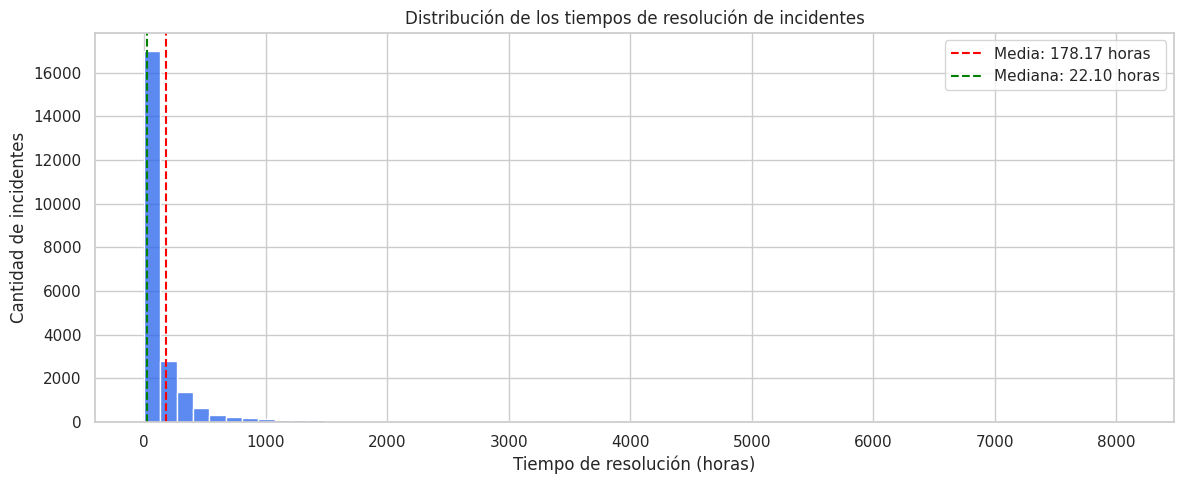

In [4]:
# ETAPA 2: Estadística descriptiva

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de las visualizaciones
sns.set_theme(style="whitegrid")

# Seleccionar la variable principal
tiempos = datos_limpios["tiempo_resolucion_horas"]

# Calcular medidas estadísticas
estadisticas = pd.DataFrame({
    "Medida estadística": [
        "Cantidad de incidentes",
        "Media",
        "Mediana",
        "Moda",
        "Mínimo",
        "Máximo",
        "Rango",
        "Varianza",
        "Desviación estándar",
        "Primer cuartil (Q1)",
        "Tercer cuartil (Q3)",
        "Rango intercuartílico (IQR)",
        "Coeficiente de variación (%)",
        "Asimetría"
    ],
    "Resultado": [
        tiempos.count(),
        tiempos.mean(),
        tiempos.median(),
        tiempos.mode().iloc[0],
        tiempos.min(),
        tiempos.max(),
        tiempos.max() - tiempos.min(),
        tiempos.var(),
        tiempos.std(),
        tiempos.quantile(0.25),
        tiempos.quantile(0.75),
        tiempos.quantile(0.75) - tiempos.quantile(0.25),
        (tiempos.std() / tiempos.mean()) * 100,
        tiempos.skew()
    ]
})

print("ESTADÍSTICAS DESCRIPTIVAS")
display(estadisticas.round(4))

# Indicadores operativos
print("\nINDICADORES DE GESTIÓN DE INCIDENTES")

print("Incidentes resueltos en máximo 24 horas:",
      round((tiempos <= 24).mean() * 100, 2), "%")

print("Incidentes resueltos en máximo 48 horas:",
      round((tiempos <= 48).mean() * 100, 2), "%")

print("Incidentes que superan 7 días:",
      round((tiempos > 168).mean() * 100, 2), "%")

print("Incidentes con cumplimiento de SLA registrado:",
      round(datos_limpios["made_sla"].mean() * 100, 2), "%")

# Distribución de los tiempos de resolución
plt.figure(figsize=(12, 5))

sns.histplot(tiempos, bins=60, color="#2563EB")

plt.axvline(
    tiempos.mean(),
    color="red",
    linestyle="--",
    label=f"Media: {tiempos.mean():.2f} horas"
)

plt.axvline(
    tiempos.median(),
    color="green",
    linestyle="--",
    label=f"Mediana: {tiempos.median():.2f} horas"
)

plt.title("Distribución de los tiempos de resolución de incidentes")
plt.xlabel("Tiempo de resolución (horas)")
plt.ylabel("Cantidad de incidentes")
plt.legend()
plt.tight_layout()
plt.show()


### 2.2. Interpretación de los resultados estadísticos

El análisis estadístico de los 23.362 incidentes permitió identificar los siguientes hallazgos:

**Medidas de tendencia central**

- La media del tiempo de resolución es de 178,17 horas, equivalente a aproximadamente 7,42 días.
- La mediana es de 22,10 horas, lo que indica que la mitad de los incidentes se resuelve en este tiempo o menos.
- La moda corresponde aproximadamente a 4 minutos.

**Medidas de dispersión**

- El rango es de 8.070,17 horas.
- La varianza es de 283.862,81 horas cuadradas.
- La desviación estándar es de 532,79 horas.
- El coeficiente de variación es del 299,03 %, lo que evidencia una elevada heterogeneidad en los tiempos de resolución.

**Distribución de los datos**

El coeficiente de asimetría de 6,93 y el histograma evidencian una distribución fuertemente sesgada hacia la derecha. Existe una concentración de incidentes con tiempos relativamente bajos y una cola extensa de incidentes con tiempos de resolución elevados.

Debido a esta asimetría, la mediana resulta más representativa que la media para describir el tiempo típico de resolución.

**Indicadores de gestión**

- El 51,67 % de los incidentes se resuelve en máximo 24 horas.
- El 59,52 % se resuelve en máximo 48 horas.
- El 22,94 % supera los siete días de resolución.
- El 61,78 % registra cumplimiento del acuerdo de nivel de servicio (SLA).

Desde una perspectiva profesional, estos resultados permiten identificar oportunidades de mejora en la gestión de incidentes, la asignación de recursos y el seguimiento de los acuerdos de nivel de servicio.

### 2.3. Identificación de valores atípicos y comparación de variables

Se utiliza el método del rango intercuartílico (IQR) para identificar valores atípicos en los tiempos de resolución.

Los valores atípicos no se eliminan automáticamente, debido a que pueden representar incidentes reales de alta complejidad o dificultades operativas.

Adicionalmente, se comparan los tiempos de resolución según la prioridad de los incidentes, se analiza el cumplimiento de los acuerdos de nivel de servicio y se explora la relación entre las variables numéricas.

Este análisis permite formular hipótesis e identificar posibles factores asociados con los tiempos de resolución.

ANÁLISIS DE VALORES ATÍPICOS
Límite inferior: -221.68
Límite superior: 370.57
Cantidad de outliers: 2383
Porcentaje de outliers: 10.2 %
Incidentes con tiempo de resolución igual a cero: 39


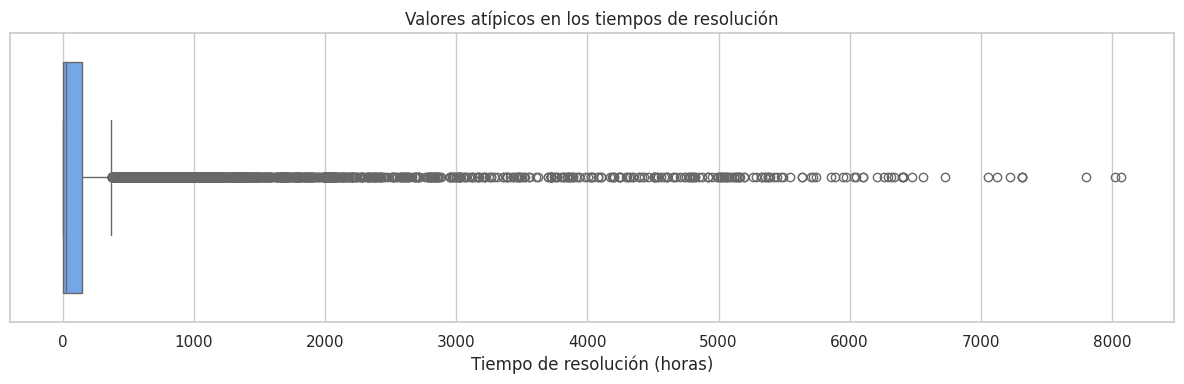


COMPARACIÓN DE INCIDENTES POR PRIORIDAD


,Incidentes,Media_horas,Mediana_horas,Desviacion,Cumplimiento_SLA
priority,,,,,
1 - Critical,270,266.08,80.24,592.56,1.85
2 - High,408,152.46,38.23,299.29,0.49
3 - Moderate,22010,174.35,21.55,518.76,63.03
4 - Low,674,283.19,5.02,918.20,81.75


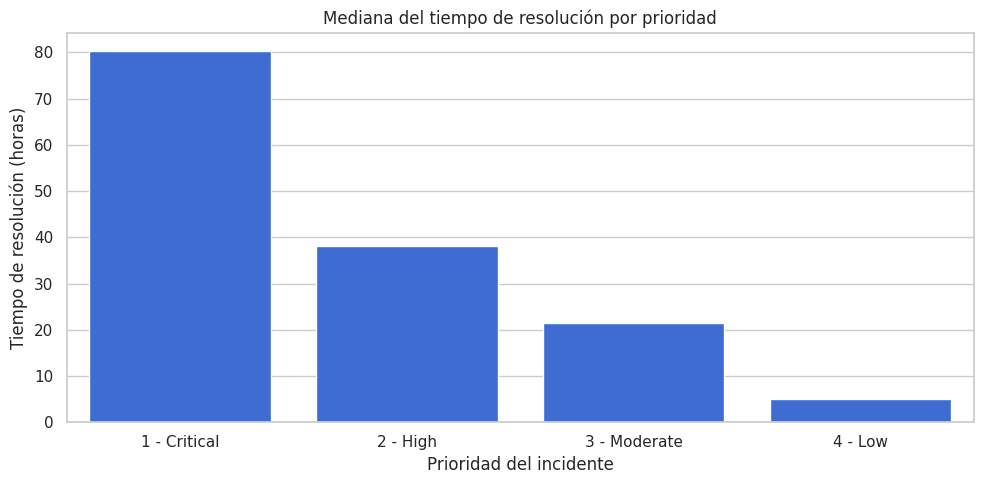

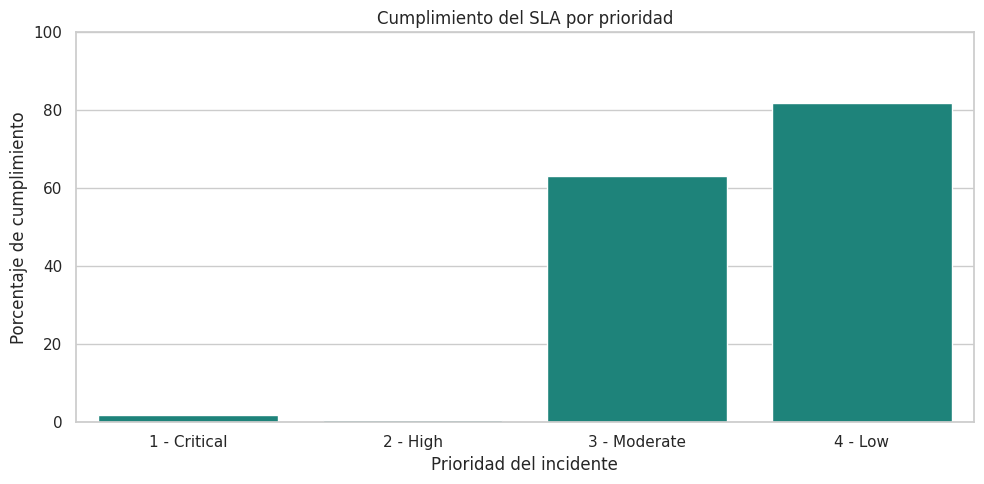


MATRIZ DE CORRELACIÓN DE SPEARMAN


,reassignment_count,reopen_count,sys_mod_count,tiempo_resolucion_horas
reassignment_count,1.000,0.085,0.654,0.528
reopen_count,0.085,1.000,0.143,0.105
sys_mod_count,0.654,0.143,1.000,0.848
tiempo_resolucion_horas,0.528,0.105,0.848,1.000


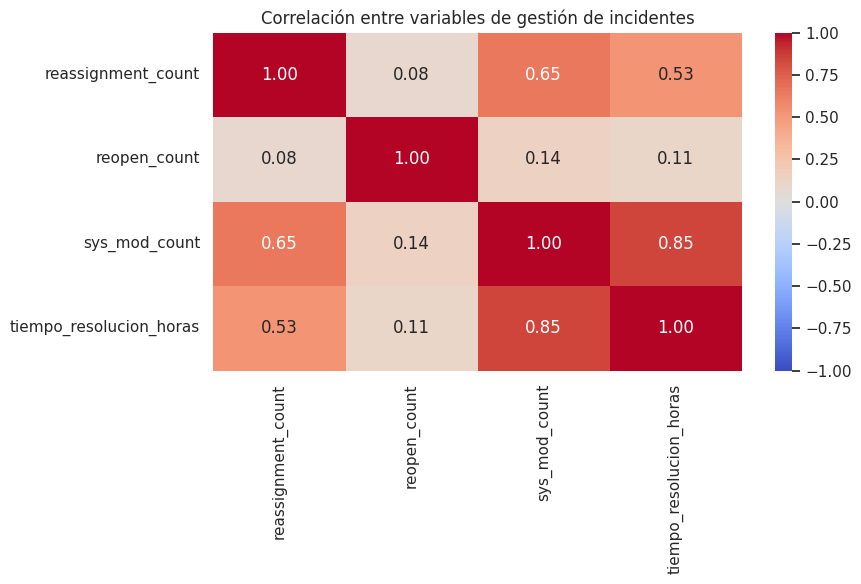

In [5]:
# Identificación de valores atípicos mediante IQR

Q1 = tiempos.quantile(0.25)
Q3 = tiempos.quantile(0.75)
IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

outliers = datos_limpios[
    (tiempos < limite_inferior) |
    (tiempos > limite_superior)
]

print("ANÁLISIS DE VALORES ATÍPICOS")
print("Límite inferior:", round(limite_inferior, 2))
print("Límite superior:", round(limite_superior, 2))
print("Cantidad de outliers:", len(outliers))
print("Porcentaje de outliers:",
      round(len(outliers) / len(datos_limpios) * 100, 2), "%")

print("Incidentes con tiempo de resolución igual a cero:",
      (tiempos == 0).sum())

# Diagrama de cajas
plt.figure(figsize=(12, 4))
sns.boxplot(x=tiempos, color="#60A5FA")
plt.title("Valores atípicos en los tiempos de resolución")
plt.xlabel("Tiempo de resolución (horas)")
plt.tight_layout()
plt.show()

# Comparación por prioridad
resumen_prioridad = datos_limpios.groupby("priority").agg(
    Incidentes=("number", "count"),
    Media_horas=("tiempo_resolucion_horas", "mean"),
    Mediana_horas=("tiempo_resolucion_horas", "median"),
    Desviacion=("tiempo_resolucion_horas", "std"),
    Cumplimiento_SLA=("made_sla", "mean")
)

resumen_prioridad["Cumplimiento_SLA"] *= 100

print("\nCOMPARACIÓN DE INCIDENTES POR PRIORIDAD")
display(resumen_prioridad.round(2))

# Gráfico de tiempos por prioridad
plt.figure(figsize=(10, 5))

sns.barplot(
    x=resumen_prioridad.index,
    y=resumen_prioridad["Mediana_horas"],
    color="#2563EB"
)

plt.title("Mediana del tiempo de resolución por prioridad")
plt.xlabel("Prioridad del incidente")
plt.ylabel("Tiempo de resolución (horas)")
plt.tight_layout()
plt.show()

# Cumplimiento del SLA por prioridad
plt.figure(figsize=(10, 5))

sns.barplot(
    x=resumen_prioridad.index,
    y=resumen_prioridad["Cumplimiento_SLA"],
    color="#0D9488"
)

plt.title("Cumplimiento del SLA por prioridad")
plt.xlabel("Prioridad del incidente")
plt.ylabel("Porcentaje de cumplimiento")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

# Análisis de correlaciones
variables_numericas = [
    "reassignment_count",
    "reopen_count",
    "sys_mod_count",
    "tiempo_resolucion_horas"
]

correlaciones = datos_limpios[
    variables_numericas
].corr(method="spearman")

print("\nMATRIZ DE CORRELACIÓN DE SPEARMAN")
display(correlaciones.round(3))

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlaciones,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Correlación entre variables de gestión de incidentes")
plt.tight_layout()
plt.show()


### 2.4. Interpretación de valores atípicos y relaciones entre variables

**Identificación de valores atípicos**

Mediante el método del rango intercuartílico (IQR), se identificaron 2.383 incidentes atípicos, equivalentes al 10,20 % del conjunto de datos depurado.

El límite superior establecido fue de 370,57 horas, aproximadamente 15,44 días.

Se decidió conservar estos registros, debido a que pueden representar situaciones reales de alta complejidad y son relevantes para la identificación de oportunidades de mejora.

También se identificaron 39 incidentes con tiempos de resolución iguales a cero, los cuales requieren una validación adicional para determinar si corresponden a resoluciones inmediatas o inconsistencias en el registro de la información.

**Comparación por prioridad**

Los incidentes críticos presentan una mediana de resolución de 80,24 horas, seguidos por los incidentes de prioridad alta con 38,23 horas, moderada con 21,55 horas y baja con 5,02 horas.

En cuanto al cumplimiento del SLA registrado, los incidentes críticos presentan un cumplimiento del 1,85 % y los de prioridad alta del 0,49 %. Estos resultados contrastan con los incidentes de prioridad moderada y baja, cuyos porcentajes son del 63,03 % y 81,75 %, respectivamente.

Estos hallazgos sugieren la necesidad de revisar los mecanismos de escalamiento, asignación de recursos, atención de incidentes prioritarios y condiciones de los acuerdos de servicio.

**Análisis de correlación**

La correlación de Spearman permitió identificar las siguientes asociaciones con el tiempo de resolución:

- Número de modificaciones: 0,848, asociación positiva fuerte.
- Número de reasignaciones: 0,528, asociación positiva moderada.
- Número de reaperturas: 0,105, asociación positiva débil.

Estas relaciones no demuestran causalidad, pero permiten formular hipótesis sobre la complejidad de los incidentes y la eficiencia de los procesos de soporte técnico.

**Hipótesis de análisis**

Los incidentes con mayor cantidad de modificaciones y reasignaciones tienden a presentar tiempos de resolución más prolongados.

**Conclusión de la etapa 2**

El análisis estadístico permitió identificar patrones de comportamiento, valores extremos y oportunidades de mejora en la gestión de incidentes tecnológicos, estableciendo las bases para el desarrollo de un modelo predictivo.

## ETAPA 3. Modelado matemático y storytelling

### 3.1. Enfoque predictivo y aplicación profesional

A partir de los resultados obtenidos en las etapas de exploración y análisis estadístico, se propone desarrollar un modelo predictivo que permita estimar los tiempos de resolución de incidentes tecnológicos y evaluar su utilidad en la gestión de servicios de TI.

El enfoque diferencial del proyecto consiste en transformar los hallazgos estadísticos en información útil para la toma de decisiones, permitiendo identificar posibles demoras, optimizar la asignación de recursos y apoyar el cumplimiento de los acuerdos de niveles de servicio (SLA).

**Pregunta de investigación:**

¿Cómo puede un responsable de tecnología utilizar la ciencia de datos para anticipar demoras en la resolución de incidentes, optimizar los procesos de escalamiento y mejorar el cumplimiento de los acuerdos de niveles de servicio?

**Hipótesis de trabajo:**

Las características disponibles al momento de registrar un incidente, como su prioridad, impacto, urgencia, categoría y canal de atención, pueden aportar información para estimar su tiempo de resolución.

El modelo será evaluado utilizando datos de prueba independientes, evitando incorporar como predictores variables que solo se conocen después de la resolución del incidente.

### 3.2. Preparación de las variables para el modelo predictivo

Para desarrollar el modelo se establece como variable dependiente el tiempo de resolución de los incidentes, expresado en horas.

Como variables independientes se seleccionan la prioridad, el impacto, la urgencia, la categoría, el canal de atención, la hora y el día de apertura del incidente.

Se recuperan las características del primer registro de cada incidente para evitar utilizar información generada durante o después de su resolución.

Las variables categóricas serán transformadas mediante la técnica One-Hot Encoding, permitiendo su procesamiento mediante algoritmos de aprendizaje automático.

El conjunto de datos se dividirá en un 80 % para entrenamiento y un 20 % para pruebas, utilizando una separación cronológica para evaluar la capacidad del modelo frente a incidentes posteriores.

In [6]:
# Preparación de los datos para el modelo predictivo

import pandas as pd
import numpy as np

# Recuperar las características iniciales de cada incidente
datos_iniciales = data.copy()

datos_iniciales["sys_updated_at"] = pd.to_datetime(
    datos_iniciales["sys_updated_at"],
    dayfirst=True,
    errors="coerce"
)

datos_iniciales = datos_iniciales.sort_values(
    ["number", "sys_mod_count", "sys_updated_at"]
).drop_duplicates(subset="number", keep="first")

# Seleccionar las variables disponibles al inicio
variables_iniciales = [
    "number",
    "priority",
    "impact",
    "urgency",
    "category",
    "contact_type",
    "opened_at"
]

# Integrar los datos iniciales con el tiempo real de resolución
datos_modelo = datos_iniciales[variables_iniciales].merge(
    datos_limpios[["number", "tiempo_resolucion_horas"]],
    on="number",
    how="inner",
    validate="one_to_one"
)

# Transformar la fecha de apertura
datos_modelo["opened_at"] = pd.to_datetime(
    datos_modelo["opened_at"],
    dayfirst=True,
    errors="coerce"
)

datos_modelo = datos_modelo.dropna(
    subset=["opened_at"]
).copy()

# Generar nuevas variables a partir de la fecha
datos_modelo["hora_apertura"] = (
    datos_modelo["opened_at"].dt.hour
)

datos_modelo["dia_semana"] = (
    datos_modelo["opened_at"].dt.dayofweek
)

# Variables categóricas
variables_categoricas = [
    "priority",
    "impact",
    "urgency",
    "category",
    "contact_type"
]

# Manejo de valores faltantes
datos_modelo[variables_categoricas] = (
    datos_modelo[variables_categoricas]
    .fillna("Desconocido")
    .astype(str)
)

# Orden cronológico
datos_modelo = datos_modelo.sort_values(
    "opened_at"
).reset_index(drop=True)

# Definir variables predictoras
variables_predictoras = variables_categoricas + [
    "hora_apertura",
    "dia_semana"
]

# Variable independiente y dependiente
X = datos_modelo[variables_predictoras]
y = datos_modelo["tiempo_resolucion_horas"]

# División cronológica: 80% entrenamiento y 20% prueba
corte = int(len(datos_modelo) * 0.80)

X_train = X.iloc[:corte]
X_test = X.iloc[corte:]

y_train = y.iloc[:corte]
y_test = y.iloc[corte:]

# Visualización de resultados
print("PREPARACIÓN DEL MODELO PREDICTIVO")
print("-" * 45)

print("Total de incidentes:", len(datos_modelo))
print("Variables predictoras:", X.shape[1])
print("Registros de entrenamiento:", len(X_train))
print("Registros de prueba:", len(X_test))
print("Valores nulos en predictores:", X.isna().sum().sum())

print("\nPeriodo de entrenamiento:")
print(datos_modelo["opened_at"].iloc[:corte].min())
print(datos_modelo["opened_at"].iloc[:corte].max())

print("\nPeriodo de prueba:")
print(datos_modelo["opened_at"].iloc[corte:].min())
print(datos_modelo["opened_at"].iloc[corte:].max())

print("\nPrimeros registros preparados:")
display(datos_modelo.head())

PREPARACIÓN DEL MODELO PREDICTIVO
---------------------------------------------
Total de incidentes: 23362
Variables predictoras: 7
Registros de entrenamiento: 18689
Registros de prueba: 4673
Valores nulos en predictores: 0

Periodo de entrenamiento:
2016-02-29 01:16:00
2016-05-11 10:30:00

Periodo de prueba:
2016-05-11 10:32:00
2017-02-16 14:17:00

Primeros registros preparados:


,number,priority,impact,urgency,category,contact_type,opened_at,tiempo_resolucion_horas,hora_apertura,dia_semana
0,INC0000045,3 - Moderate,2 - Medium,2 - Medium,Category 55,Phone,2016-02-29 01:16:00,10.216667,1,0
1,INC0000047,3 - Moderate,2 - Medium,2 - Medium,Category 40,Phone,2016-02-29 04:40:00,29.200000,4,0
2,INC0000057,3 - Moderate,2 - Medium,2 - Medium,Category 20,Phone,2016-02-29 06:10:00,20.750000,6,0
3,INC0000060,3 - Moderate,2 - Medium,2 - Medium,Category 9,Phone,2016-02-29 06:38:00,53.466667,6,0
4,INC0000062,3 - Moderate,2 - Medium,2 - Medium,Category 53,Phone,2016-02-29 06:58:00,8.883333,6,0


### 3.3. Entrenamiento y evaluación del modelo predictivo

Se implementa un modelo de regresión lineal múltiple para estimar el tiempo de resolución de los incidentes tecnológicos a partir de sus características iniciales.

Como referencia de comparación se utiliza un modelo base que predice la mediana histórica de los tiempos de resolución.

Para garantizar una evaluación temporal realista, solo se utilizarán para el entrenamiento aquellos incidentes cuyo tiempo de resolución ya era conocido antes del inicio del periodo de prueba.

El desempeño será evaluado mediante tres indicadores:

- MAE: error absoluto medio de las predicciones.
- RMSE: raíz del error cuadrático medio, que penaliza los errores de mayor magnitud.
- R²: coeficiente de determinación, que permite evaluar la capacidad explicativa del modelo.

El objetivo no es garantizar una predicción exacta, sino determinar si el análisis predictivo puede aportar valor a la planificación y gestión de los servicios de TI.

In [7]:
# Entrenamiento y evaluación del modelo predictivo

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Evitar utilizar resultados que aún no eran conocidos
# al inicio del periodo de prueba

fecha_corte = datos_modelo["opened_at"].iloc[corte]

fecha_resolucion = (
    datos_modelo["opened_at"]
    + pd.to_timedelta(
        datos_modelo["tiempo_resolucion_horas"],
        unit="h"
    )
)

disponibles = (
    fecha_resolucion.iloc[:corte] < fecha_corte
)

X_train_valido = X_train.loc[disponibles]
y_train_valido = y_train.loc[disponibles]

print("Registros disponibles para entrenamiento:",
      len(X_train_valido))

print("Registros excluidos por control temporal:",
      len(X_train) - len(X_train_valido))

# Transformación de las variables categóricas
preprocesador = ColumnTransformer(
    transformers=[
        (
            "categoricas",
            OneHotEncoder(handle_unknown="ignore"),
            variables_categoricas
        ),
        (
            "numericas",
            "passthrough",
            ["hora_apertura", "dia_semana"]
        )
    ]
)

# Construcción del modelo de regresión lineal
modelo = Pipeline([
    ("preprocesamiento", preprocesador),
    ("regresion", LinearRegression())
])

# Entrenamiento
modelo.fit(X_train_valido, y_train_valido)

# Generación de predicciones
predicciones_originales = modelo.predict(X_test)

# Los tiempos negativos no son válidos
predicciones = np.maximum(
    predicciones_originales, 0
)

# Modelo de referencia basado en la mediana
modelo_base = DummyRegressor(strategy="median")

modelo_base.fit(X_train_valido, y_train_valido)

predicciones_base = modelo_base.predict(X_test)

# Función para evaluar el desempeño
def evaluar_modelo(nombre, reales, estimados):
    return {
        "Modelo": nombre,
        "MAE (horas)": mean_absolute_error(
            reales, estimados
        ),
        "RMSE (horas)": np.sqrt(
            mean_squared_error(reales, estimados)
        ),
        "R2": r2_score(reales, estimados)
    }

# Comparación de resultados
resultados_modelos = pd.DataFrame([
    evaluar_modelo(
        "Modelo base - Mediana",
        y_test,
        predicciones_base
    ),
    evaluar_modelo(
        "Regresión lineal",
        y_test,
        predicciones
    )
])

print("\nRESULTADOS DE LOS MODELOS")
display(resultados_modelos.round(4))

# Comparación del error absoluto medio
mae_base = mean_absolute_error(
    y_test, predicciones_base
)

mae_modelo = mean_absolute_error(
    y_test, predicciones
)

mejora = (
    (mae_base - mae_modelo) / mae_base
) * 100

print("\nVariación porcentual del MAE frente al modelo base:")
print(round(mejora, 2), "%")

print("\nMediana histórica de referencia:")
print(round(np.median(y_train_valido), 2), "horas")

print("\nPredicciones negativas corregidas:")
print((predicciones_originales < 0).sum())

# Comparación de valores reales y predichos
resultados_prediccion = (
    datos_modelo.iloc[corte:][
        ["number", "priority", "category"]
    ].copy()
)

resultados_prediccion["Tiempo_real_horas"] = (
    y_test.to_numpy()
)

resultados_prediccion["Tiempo_estimado_horas"] = (
    predicciones
)

resultados_prediccion["Error_absoluto_horas"] = (
    np.abs(y_test.to_numpy() - predicciones)
)

print("\nPRIMERAS 10 PREDICCIONES")
display(resultados_prediccion.head(10).round(2))

Registros disponibles para entrenamiento: 17349
Registros excluidos por control temporal: 1340

RESULTADOS DE LOS MODELOS


,Modelo,MAE (horas),RMSE (horas),R2
0,Modelo base - Mediana,134.3691,455.6310,-0.0635
1,Regresión lineal,157.3241,438.0293,0.0170



Variación porcentual del MAE frente al modelo base:
-17.08 %

Mediana histórica de referencia:
21.12 horas

Predicciones negativas corregidas:
2

PRIMERAS 10 PREDICCIONES


,number,priority,category,Tiempo_real_horas,Tiempo_estimado_horas,Error_absoluto_horas
18689,INC0028311,3 - Moderate,Category 9,30.78,100.90,70.12
18690,INC0028312,3 - Moderate,Category 24,3000.33,110.98,2889.36
18691,INC0028313,3 - Moderate,Category 61,28.63,146.40,117.77
18692,INC0028315,3 - Moderate,Category 46,557.87,140.79,417.08
18693,INC0028314,3 - Moderate,Category 61,27.85,146.40,118.55
18694,INC0028316,3 - Moderate,Category 46,5.58,140.79,135.21
18695,INC0028317,3 - Moderate,Category 26,23.10,75.61,52.51
18696,INC0028319,3 - Moderate,Category 9,1.47,100.90,99.44
18697,INC0028320,3 - Moderate,Category 37,2.48,89.75,87.26
18698,INC0028321,3 - Moderate,Category 40,0.30,174.25,173.95


### 3.4. Interpretación de los resultados del modelo predictivo

El modelo de regresión lineal fue entrenado con 17.349 incidentes históricos y evaluado sobre 4.673 incidentes posteriores. Se excluyeron 1.340 registros del entrenamiento mediante un control temporal para evitar utilizar información que aún no estaba disponible.

Los resultados obtenidos muestran un error absoluto medio (MAE) de 157,32 horas para la regresión lineal, frente a 134,37 horas del modelo base. Esto representa un incremento del error del 17,08 %.

Por otra parte, el RMSE disminuyó de 455,63 a 438,03 horas, evidenciando una ligera mejora en una métrica que penaliza especialmente los errores de mayor magnitud.

El coeficiente de determinación R² fue de 0,017, lo que indica que el modelo explica aproximadamente el 1,7 % de la variabilidad de los tiempos de resolución en el conjunto de prueba.

Estos resultados sugieren que las características disponibles al momento de registrar un incidente son insuficientes, bajo el modelo lineal utilizado, para realizar estimaciones individuales confiables.

Desde una perspectiva profesional, se plantea complementar la información inicial con variables operativas como la disponibilidad del personal técnico, la carga de trabajo, la complejidad del incidente y los tiempos de escalamiento.

El modelo constituye una primera aproximación experimental y no se recomienda su implementación directa como herramienta autónoma de toma de decisiones.

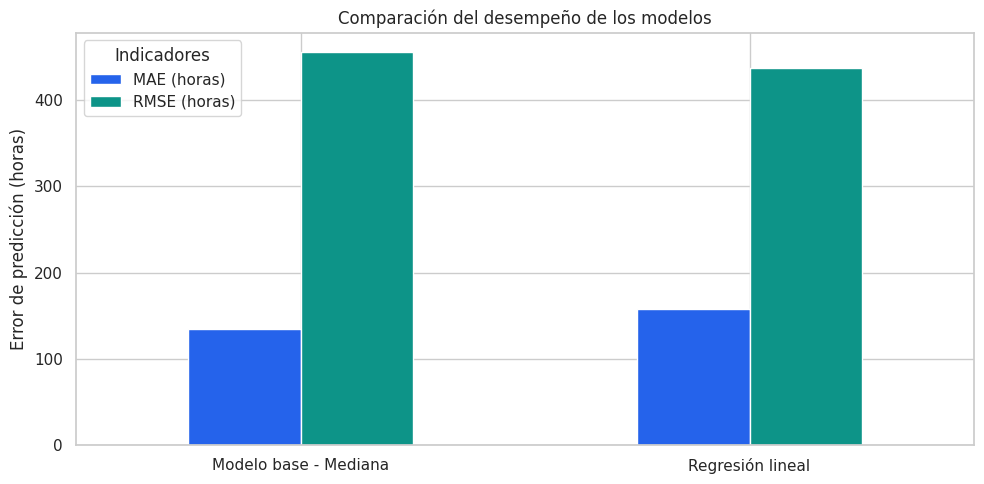

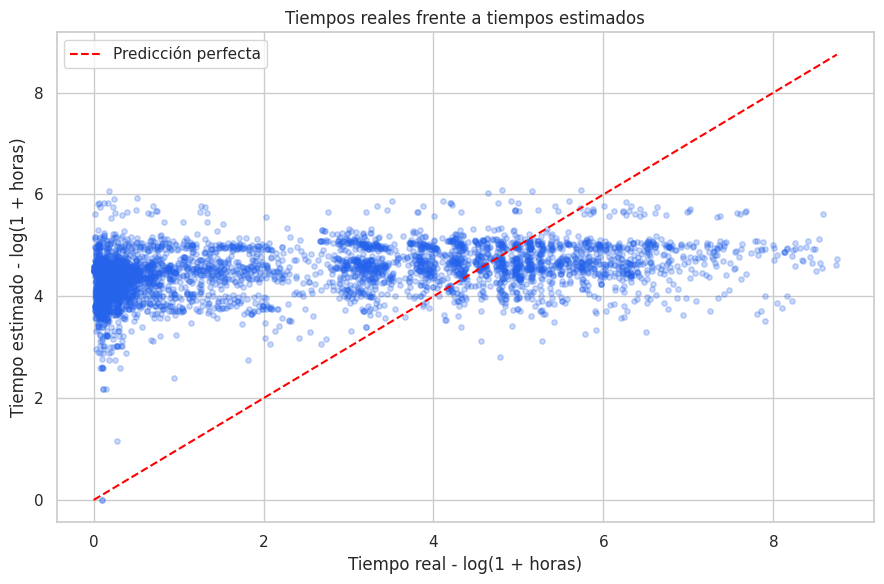

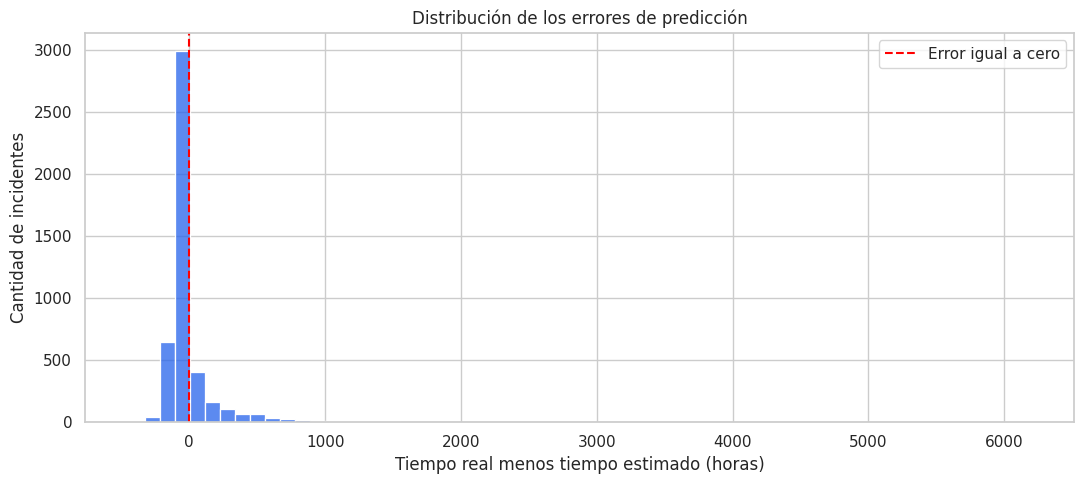

In [8]:
# Visualizaciones de evaluación del modelo predictivo

# Gráfico 1: comparación de errores

resultados_modelos.set_index("Modelo")[
    ["MAE (horas)", "RMSE (horas)"]
].plot(
    kind="bar",
    figsize=(10, 5),
    color=["#2563EB", "#0D9488"],
    rot=0
)

plt.title("Comparación del desempeño de los modelos")
plt.ylabel("Error de predicción (horas)")
plt.xlabel("")
plt.legend(title="Indicadores")
plt.tight_layout()
plt.show()

# Gráfico 2: tiempos reales frente a tiempos estimados
# Escala logarítmica para visualizar los valores extremos

plt.figure(figsize=(9, 6))

plt.scatter(
    np.log1p(y_test),
    np.log1p(predicciones),
    alpha=0.25,
    color="#2563EB",
    s=15
)

limite = max(
    np.log1p(y_test).max(),
    np.log1p(predicciones).max()
)

plt.plot(
    [0, limite],
    [0, limite],
    color="red",
    linestyle="--",
    label="Predicción perfecta"
)

plt.title("Tiempos reales frente a tiempos estimados")
plt.xlabel("Tiempo real - log(1 + horas)")
plt.ylabel("Tiempo estimado - log(1 + horas)")
plt.legend()
plt.tight_layout()
plt.show()

# Gráfico 3: distribución de los errores

errores = y_test.to_numpy() - predicciones

plt.figure(figsize=(11, 5))

sns.histplot(
    errores,
    bins=60,
    color="#2563EB"
)

plt.axvline(
    0,
    color="red",
    linestyle="--",
    label="Error igual a cero"
)

plt.title("Distribución de los errores de predicción")
plt.xlabel("Tiempo real menos tiempo estimado (horas)")
plt.ylabel("Cantidad de incidentes")
plt.legend()
plt.tight_layout()
plt.show()

## 4. Storytelling y aplicación profesional

### 4.1. De los datos a la toma de decisiones en tecnología

El análisis realizado permite comprender que la gestión de incidentes tecnológicos no debe evaluarse únicamente mediante los tiempos promedio de resolución, sino también mediante la identificación de comportamientos, desviaciones y condiciones operativas que puedan afectar la continuidad de los servicios.

A partir de los 23.362 incidentes analizados, se identificaron los siguientes hallazgos:

- El 51,67 % de los incidentes se resolvió en un plazo máximo de 24 horas.
- El 22,94 % presentó tiempos de resolución superiores a siete días.
- El cumplimiento de los acuerdos de nivel de servicio (SLA) registrado fue del 61,78 %.
- Los incidentes de prioridad crítica presentaron una mediana de resolución de 80,24 horas.
- El número de modificaciones y reasignaciones presentó una asociación positiva con los tiempos de resolución.

Aunque el modelo predictivo desarrollado presentó limitaciones para estimar con precisión la duración individual de los incidentes, el análisis estadístico permitió identificar señales relevantes para fortalecer la gestión operativa.

En consecuencia, se propone complementar el enfoque predictivo con una estrategia de seguimiento preventivo, orientada a identificar incidentes que requieran atención, escalamiento o intervención oportuna por parte de los responsables de tecnología.

Esta propuesta busca transformar los resultados de la ciencia de datos en información útil para la toma de decisiones, la mejora continua y la continuidad de los servicios tecnológicos.


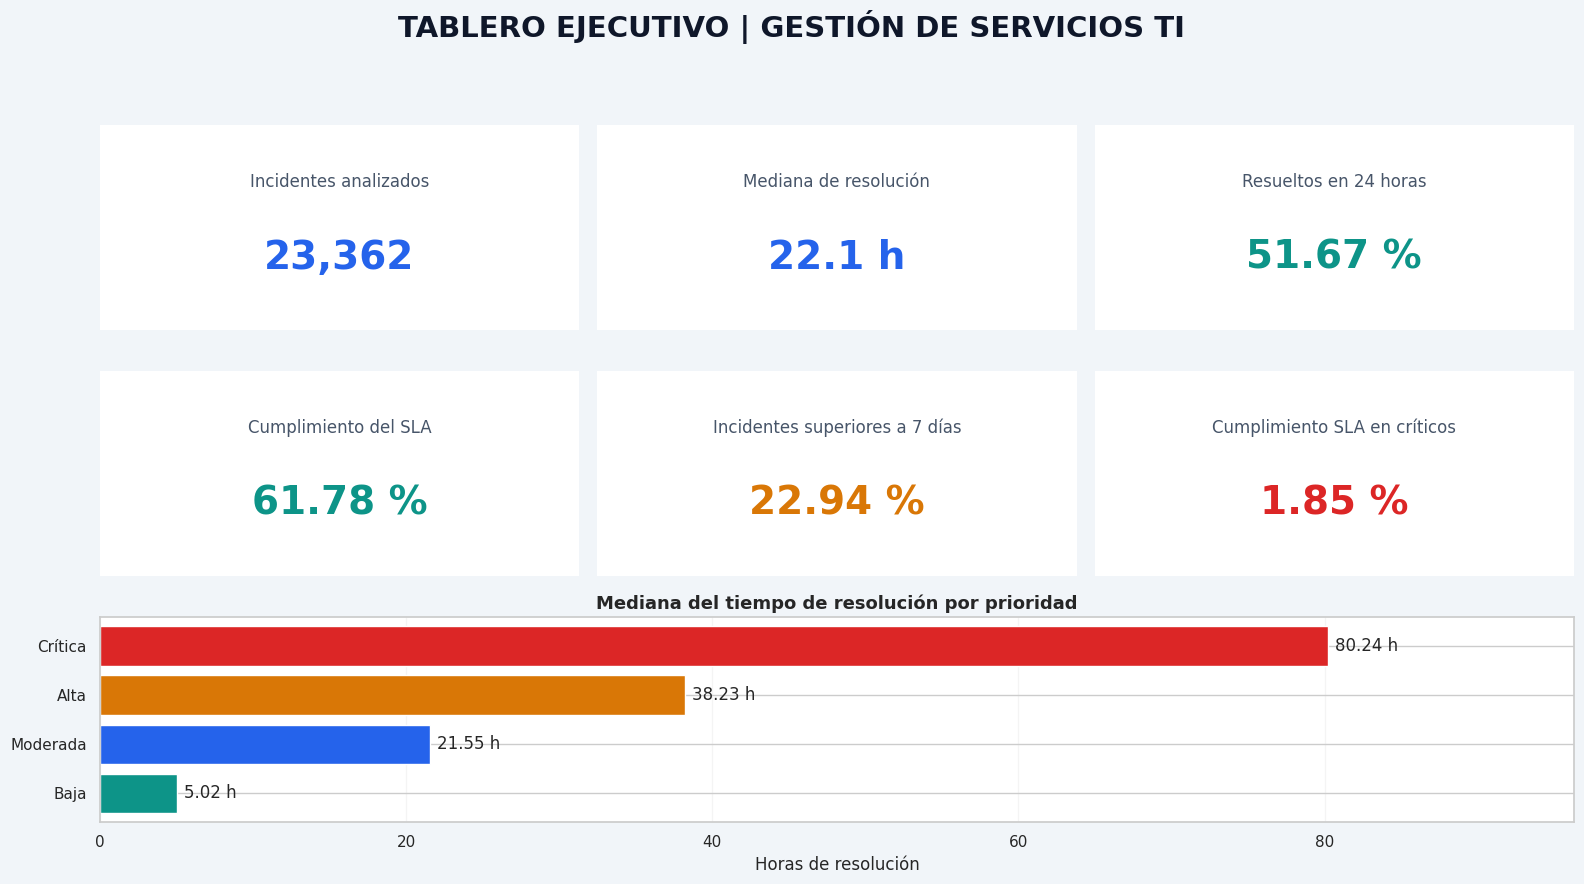

In [9]:
# Tablero ejecutivo de gestión de incidentes TI

from matplotlib.gridspec import GridSpec

fig = plt.figure(figsize=(16, 9), facecolor="#F1F5F9")
gs = GridSpec(3, 3, figure=fig)

fig.suptitle(
    "TABLERO EJECUTIVO | GESTIÓN DE SERVICIOS TI",
    fontsize=21,
    fontweight="bold",
    color="#0F172A"
)

indicadores = [
    ("Incidentes analizados",
     f"{len(datos_limpios):,}", "#2563EB"),

    ("Mediana de resolución",
     f"{tiempos.median():.1f} h", "#2563EB"),

    ("Resueltos en 24 horas",
     f"{(tiempos <= 24).mean()*100:.2f} %", "#0D9488"),

    ("Cumplimiento del SLA",
     f"{datos_limpios['made_sla'].mean()*100:.2f} %", "#0D9488"),

    ("Incidentes superiores a 7 días",
     f"{(tiempos > 168).mean()*100:.2f} %", "#D97706"),

    ("Cumplimiento SLA en críticos",
     f"{resumen_prioridad.loc['1 - Critical', 'Cumplimiento_SLA']:.2f} %",
     "#DC2626")
]

# Tarjetas de indicadores

for i, (titulo, valor, color) in enumerate(indicadores):

    ax = fig.add_subplot(gs[i // 3, i % 3])
    ax.set_facecolor("white")
    ax.set_xticks([])
    ax.set_yticks([])

    for borde in ax.spines.values():
        borde.set_visible(False)

    ax.text(
        0.5, 0.70, titulo,
        ha="center",
        fontsize=12,
        color="#475569",
        transform=ax.transAxes
    )

    ax.text(
        0.5, 0.30, valor,
        ha="center",
        fontsize=28,
        fontweight="bold",
        color=color,
        transform=ax.transAxes
    )

# Gráfico de tiempos de resolución por prioridad

ax = fig.add_subplot(gs[2, :])

prioridades = ["Crítica", "Alta", "Moderada", "Baja"]

barras = ax.barh(
    prioridades,
    resumen_prioridad["Mediana_horas"],
    color=["#DC2626", "#D97706", "#2563EB", "#0D9488"]
)

ax.invert_yaxis()

ax.set_title(
    "Mediana del tiempo de resolución por prioridad",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel("Horas de resolución")
ax.set_xlim(0, resumen_prioridad["Mediana_horas"].max() * 1.2)

ax.bar_label(barras, fmt="%.2f h", padding=5)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout(rect=[0, 0, 1, 0.93])

# Guardar el tablero como evidencia
plt.savefig(
    "tablero_ejecutivo_incidentes_TI.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 4.4. Propuesta de un sistema de alertas preventivas

Como componente diferenciador del proyecto, se propone un sistema de semaforización para el seguimiento, control y escalamiento oportuno de incidentes tecnológicos.

La propuesta surge de los resultados del análisis estadístico y de las limitaciones identificadas durante la evaluación del modelo predictivo.

El sistema establece tres niveles de seguimiento:

- Verde: incidente dentro del tiempo de atención preventiva.
- Amarillo: incidente que requiere revisión y seguimiento prioritario.
- Rojo: incidente que requiere escalamiento e intervención oportuna.

Los umbrales de alerta se establecen de manera diferenciada según la prioridad del incidente.

Estos tiempos constituyen una propuesta académica de gestión operativa y deberán validarse frente a los acuerdos de nivel de servicio y las capacidades de cada organización.

El objetivo es facilitar la toma de decisiones, reducir los riesgos operativos, mejorar los tiempos de atención y contribuir a la continuidad de los servicios tecnológicos.

SIMULACIÓN RETROSPECTIVA DE ALERTAS


,Incidentes,Porcentaje
nivel_alerta,,
Verde,10660,45.63
Amarillo,1366,5.85
Rojo,11336,48.52



PORCENTAJE DE ALERTAS POR PRIORIDAD


nivel_alerta,Verde,Amarillo,Rojo
priority,,,
1 - Critical,7.78,6.67,85.56
2 - High,20.34,8.82,70.83
3 - Moderate,46.26,5.74,48.00
4 - Low,55.49,7.27,37.24


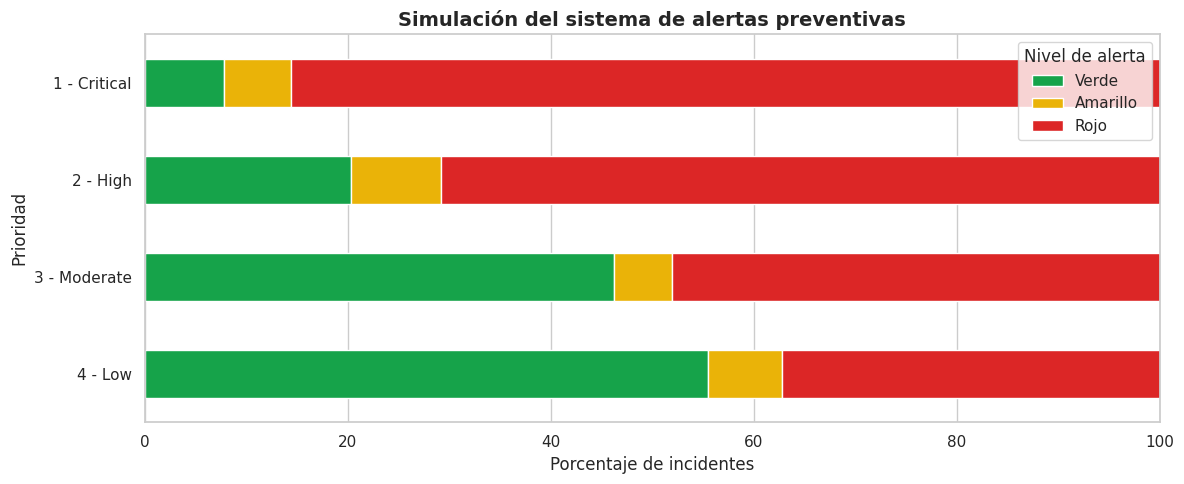

In [10]:
# Sistema propuesto de alertas preventivas

umbrales = {
    "1 - Critical": (2, 4),
    "2 - High": (4, 8),
    "3 - Moderate": (12, 24),
    "4 - Low": (24, 48)
}

# Crear una copia para la simulación retrospectiva
datos_alertas = datos_limpios.copy()

def clasificar_alerta(prioridad, horas):

    amarillo, rojo = umbrales[prioridad]

    if horas >= rojo:
        return "Rojo"

    elif horas >= amarillo:
        return "Amarillo"

    else:
        return "Verde"

# Aplicar clasificación
datos_alertas["nivel_alerta"] = datos_alertas.apply(
    lambda fila: clasificar_alerta(
        fila["priority"],
        fila["tiempo_resolucion_horas"]
    ),
    axis=1
)

# Resumen general
orden_alertas = ["Verde", "Amarillo", "Rojo"]

resumen_alertas = (
    datos_alertas["nivel_alerta"]
    .value_counts()
    .reindex(orden_alertas, fill_value=0)
    .to_frame("Incidentes")
)

resumen_alertas["Porcentaje"] = (
    resumen_alertas["Incidentes"]
    / len(datos_alertas) * 100
)

print("SIMULACIÓN RETROSPECTIVA DE ALERTAS")
display(resumen_alertas.round(2))

# Distribución por prioridad
alertas_prioridad = pd.crosstab(
    datos_alertas["priority"],
    datos_alertas["nivel_alerta"],
    normalize="index"
) * 100

alertas_prioridad = alertas_prioridad.reindex(
    columns=orden_alertas,
    fill_value=0
)

print("\nPORCENTAJE DE ALERTAS POR PRIORIDAD")
display(alertas_prioridad.round(2))

# Visualización de resultados
alertas_prioridad.plot(
    kind="barh",
    stacked=True,
    figsize=(12, 5),
    color=["#16A34A", "#EAB308", "#DC2626"]
)

plt.title(
    "Simulación del sistema de alertas preventivas",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Porcentaje de incidentes")
plt.ylabel("Prioridad")
plt.xlim(0, 100)
plt.gca().invert_yaxis()
plt.legend(title="Nivel de alerta")
plt.tight_layout()

plt.savefig(
    "sistema_alertas_preventivas_TI.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Interpretación de la simulación de alertas preventivas

Los resultados de la simulación retrospectiva muestran que el 45,63 % de los incidentes se clasifica en nivel verde, el 5,85 % en nivel amarillo y el 48,52 % en nivel rojo.

El comportamiento más preocupante se presenta en los incidentes críticos, donde el 85,56 % habría alcanzado el umbral de escalamiento, seguido de los incidentes de prioridad alta con un 70,83 %.

Estos resultados evidencian la importancia de fortalecer los mecanismos de seguimiento, priorización y escalamiento dentro de la gestión de servicios tecnológicos.

Asimismo, la elevada proporción de alertas rojas indica la necesidad de calibrar los umbrales propuestos para evitar la saturación operativa del equipo de soporte.

La simulación no demuestra una reducción efectiva de los tiempos de resolución, pero permite dimensionar las necesidades de intervención y establecer una base para futuras estrategias de mejora continua.

## 5. Conclusiones generales

El desarrollo de este proyecto permitió integrar los conocimientos adquiridos durante los tres módulos del curso de Ciencia de Datos, aplicándolos a un escenario real de gestión de servicios tecnológicos.

### 5.1. Calidad y preparación de los datos

A partir de 141.712 registros históricos, correspondientes a 24.918 incidentes únicos, se obtuvo un conjunto depurado de 23.362 incidentes y 17 variables, sin valores nulos ni duplicados por incidente.

Este proceso permitió comprender la importancia de la limpieza, transformación y consolidación de los datos como fundamento de cualquier análisis confiable.

### 5.2. Hallazgos estadísticos

La media del tiempo de resolución fue de 178,17 horas, mientras que la mediana fue de 22,10 horas. Esta diferencia evidencia una distribución con fuerte asimetría positiva, influenciada por incidentes con tiempos de resolución considerablemente elevados.

Se identificaron 2.383 valores atípicos, equivalentes al 10,20 % de los incidentes analizados.

El cumplimiento del SLA registrado fue del 61,78 %, mientras que para los incidentes críticos alcanzó únicamente el 1,85 %.

Estos resultados permiten identificar oportunidades de mejora en la gestión, priorización y seguimiento de los incidentes tecnológicos.

### 5.3. Evaluación del modelo predictivo

La regresión lineal presentó un error absoluto medio de 157,32 horas, frente a 134,37 horas del modelo de referencia basado en la mediana histórica.

Aunque la regresión redujo ligeramente el RMSE, obtuvo un coeficiente de determinación R² de 0,017, lo que evidencia una capacidad explicativa limitada.

El modelo no resulta suficientemente confiable para predecir individualmente los tiempos de resolución en un entorno operativo.

Este resultado demuestra que implementar un modelo predictivo no garantiza mejores decisiones y que su evaluación frente a una referencia sencilla es fundamental.

### 5.4. Propuesta de valor

Como alternativa complementaria, se diseñó un tablero ejecutivo y un sistema de alertas preventivas basado en la prioridad y el tiempo transcurrido del incidente.

La simulación identificó que el 48,52 % de los incidentes habría alcanzado el nivel rojo de escalamiento.

Esta propuesta permite transformar los resultados estadísticos en información útil para la toma de decisiones, sin depender exclusivamente de las predicciones de un modelo matemático.

### 5.5. Aplicación profesional

En un entorno profesional de gestión de tecnología, este enfoque podría integrarse con plataformas de mesa de ayuda, herramientas de monitoreo y soluciones de inteligencia de negocios.

Su implementación permitiría fortalecer el seguimiento de incidentes, identificar riesgos operativos, facilitar la asignación de recursos y contribuir a la continuidad de los servicios tecnológicos.

Como experiencia de aprendizaje, el proyecto demuestra que el verdadero valor de la ciencia de datos no consiste únicamente en generar estadísticas o predicciones, sino en transformar los datos en conocimiento que facilite decisiones informadas y acciones de mejora continua.

## 5. Conclusiones y reflexión personal

### 5.1. La importancia de contar con información de calidad

Uno de los primeros aprendizajes que me deja este proyecto es la importancia de conocer y organizar la información antes de comenzar a analizarla.

Inicialmente contaba con 141.712 registros, pero durante la exploración pude identificar que estos correspondían a 24.918 incidentes tecnológicos. Después del proceso de limpieza y transformación, logré consolidar una base de 23.362 incidentes con información suficiente para realizar el análisis.

Esto me permitió comprender que tener una gran cantidad de datos no necesariamente significa contar con información de calidad.

### 5.2. ¿Qué me mostraron los datos?

Uno de los resultados que más me llamó la atención fue la diferencia entre el promedio de resolución de los incidentes, que fue de 178,17 horas, y la mediana, que fue de 22,10 horas.

Aunque el 51,67 % de los incidentes se resolvió durante las primeras 24 horas, también encontré que el 22,94 % superó los siete días.

Desde mi experiencia en el área de tecnología, considero que estos tiempos prolongados pueden representar un riesgo para la operación de una organización y para la continuidad de sus servicios.

Otro resultado que considero importante es el bajo cumplimiento del SLA registrado en los incidentes críticos, que fue de apenas el 1,85 %. Esto me lleva a pensar en la necesidad de revisar cómo se priorizan, atienden y escalan este tipo de situaciones.

### 5.3. Lo que aprendí del modelo predictivo

Al iniciar el proyecto, una de mis expectativas era poder estimar el tiempo de resolución de un incidente a partir de sus características.

Sin embargo, los resultados de la regresión lineal me permitieron identificar que las variables disponibles no eran suficientes para realizar predicciones confiables con este modelo.

El error absoluto medio fue de 157,32 horas, mientras que una estimación sencilla basada en la mediana histórica obtuvo un error de 134,37 horas.

Aunque la regresión presentó una pequeña mejora en el RMSE, su capacidad predictiva fue limitada.

Considero que este resultado también hace parte del aprendizaje. No siempre un modelo matemático va a ofrecer una mejor solución y es importante reconocer sus limitaciones antes de aplicarlo en un entorno laboral.

### 5.4. De los datos a una propuesta de mejora

A partir de los resultados obtenidos, decidí complementar el análisis con un tablero ejecutivo y una propuesta de alertas preventivas.

La intención es que la información no se utilice únicamente para conocer lo que sucedió en el pasado, sino también como una herramienta de apoyo para el seguimiento de los incidentes que se presentan diariamente.

La simulación mostró que el 48,52 % de los incidentes habría alcanzado el nivel rojo de alerta, llegando al 85,56 % en los incidentes críticos.

Estos resultados me permiten plantear una estrategia de seguimiento y escalamiento oportuno, teniendo presente que los tiempos propuestos deben ajustarse a las necesidades y capacidades reales de cada organización.

### 5.5. Aplicación en mi entorno profesional

Desde mi experiencia en la gestión de tecnología, encuentro una relación directa entre lo aprendido en este curso y las actividades que realizo profesionalmente.

En muchas ocasiones contamos con información histórica de incidentes, solicitudes de soporte y diferentes eventos tecnológicos, pero no siempre aprovechamos estos datos para identificar oportunidades de mejora.

Considero que herramientas como Python, Google Colab y las técnicas de análisis estadístico pueden complementar los procesos de gestión tecnológica, ayudando a identificar comportamientos, establecer indicadores y tomar decisiones con mayor sustento.

Este proyecto me permitió entender que la ciencia de datos no consiste solamente en realizar cálculos, generar gráficos o construir modelos predictivos. Su verdadero aporte está en comprender la información y encontrar la manera de utilizarla para resolver necesidades reales.

Me queda el interés de seguir explorando estas herramientas y evaluar cómo podría incorporarlas en los procesos de gestión tecnológica, soporte y continuidad de los servicios dentro de una organización.

## 6. Exportación de los resultados

Para facilitar la consulta y reproducción del proyecto, se exportan los datos originales y los datos obtenidos después del proceso de limpieza y transformación.

Estos archivos, junto con el cuaderno de Google Colab y las evidencias gráficas, harán parte del repositorio del proyecto en GitHub.

In [11]:
# Exportación de los datos del proyecto

import os

os.makedirs("datos", exist_ok=True)

# Base de datos original
data.to_csv(
    "datos/incidentes_originales.csv",
    index=False,
    encoding="utf-8"
)

# Base de datos depurada
datos_limpios.to_csv(
    "datos/incidentes_depurados.csv",
    index=False,
    encoding="utf-8"
)

print("ARCHIVOS GENERADOS CORRECTAMENTE")
print("-" * 45)

for archivo in os.listdir("datos"):
    ruta = os.path.join("datos", archivo)
    peso = os.path.getsize(ruta) / (1024 ** 2)

    print(f"{archivo}: {peso:.2f} MB")

print("\nRegistros originales:", len(data))
print("Incidentes depurados:", len(datos_limpios))
print("Variables finales:", datos_limpios.shape[1])

ARCHIVOS GENERADOS CORRECTAMENTE
---------------------------------------------
incidentes_originales.csv: 43.22 MB
incidentes_depurados.csv: 4.15 MB

Registros originales: 141712
Incidentes depurados: 23362
Variables finales: 17


In [13]:
import zipfile
from google.colab import files

# Comprimir la base de datos original
with zipfile.ZipFile(
    "datos/incidentes_originales.zip",
    "w",
    zipfile.ZIP_DEFLATED
) as zip_file:
    zip_file.write(
        "datos/incidentes_originales.csv",
        arcname="incidentes_originales.csv"
    )

print("Base de datos original comprimida correctamente")

# Descargar ambos archivos
files.download("datos/incidentes_originales.zip")
files.download("datos/incidentes_depurados.csv")

Base de datos original comprimida correctamente


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>